# ILLM (AI463) – Lab 10 Assignment
**Introduction to LLM · Monsoon 2026 · SVNIT Surat, Dept. of AI**

### Assignment
1. Solve question 2, 4, and 5 in the midsem question paper.
2. Take the dataset built for the language identification model in Lab Assignment 1. Fine-tune a BERT model on it (Indic-BERT, MuRIL, mBERT, mT5 or XLM-RoBERTa). Compare its performance with the models built earlier: logistic regression, MLP, LSTM, GRU and FastText.

**Contents**
- Part 1 – Midsem Q2 (Beam search), Q4 (BPE), Q5 (TF-IDF / Doc2Vec): question, worked solution, and code
- Part 2 – Fine-tuning BERT (XLM-RoBERTa-base) for language identification and comparison

# Part 1 – Midsem Questions

## Question 2
You are designing a neural language model. The vocabulary is restricted to V = { cat, sat, mat, `</s>` }, where `</s>` represents the End-Of-Sentence token. The conditional probabilities P(w_t | w_1, ..., w_{t-1}) calculated by the model across three time steps are as follows:

**At t = 1**
P(cat|`<s>`) = 0.5, P(sat|`<s>`) = 0.3, P(mat|`<s>`) = 0.2 (where `<s>` is the Start-of-Sentence token and is not part of the vocabulary)

**At t = 2**
P(sat|cat) = 0.6, P(mat|cat) = 0.3, P(`</s>`|cat) = 0.1, P(cat|sat) = 0.2, P(mat|sat) = 0.7, P(`</s>`|sat) = 0.1

**At t = 3**
P(mat|cat sat) = 0.8, P(`</s>`|cat sat) = 0.2, P(cat|sat mat) = 0.1, P(`</s>`|sat mat) = 0.9

Trace the Beam Search decoding algorithm with beam width k = 2 across time steps t = 1, 2, 3. At each step, compute cumulative probabilities for all expanded hypotheses and state the top-k retained candidates. Identify the final output sequence produced by the beam search. Why do we ignore P(cat|mat) and P(sat|mat)? **[CO1] [4+1+1 = 6]**

### Solution (by hand)

Score of a hypothesis = product of the conditional probabilities along its path.

**t = 1** – candidates: cat 0.5, sat 0.3, mat 0.2 → keep **cat (0.5), sat (0.3)**; *mat (0.2) is pruned*.

**t = 2** – expand both kept hypotheses:

| Hypothesis | Computation | Score | Kept? |
|---|---|---|---|
| cat sat | 0.5 × 0.6 | **0.30** | ✔ |
| cat mat | 0.5 × 0.3 | 0.15 | ✘ |
| cat `</s>` | 0.5 × 0.1 | 0.05 | ✘ |
| sat cat | 0.3 × 0.2 | 0.06 | ✘ |
| sat mat | 0.3 × 0.7 | **0.21** | ✔ |
| sat `</s>` | 0.3 × 0.1 | 0.03 | ✘ |

**t = 3** – expand "cat sat" and "sat mat":

| Hypothesis | Computation | Score | Kept? |
|---|---|---|---|
| cat sat mat | 0.30 × 0.8 | **0.24** | ✔ |
| cat sat `</s>` | 0.30 × 0.2 | 0.06 | ✘ |
| sat mat cat | 0.21 × 0.1 | 0.021 | ✘ |
| sat mat `</s>` | 0.21 × 0.9 | **0.189** | ✔ |

**Final output:** **"cat sat mat"** with probability **0.24** (the best hypothesis in the final beam; runner-up is "sat mat `</s>`" with 0.189). Both have length 3, so length normalisation does not change the ranking.

**Why ignore P(cat|mat) and P(sat|mat)?** The hypothesis "mat" had the lowest score (0.2) at t = 1 and was pruned, because only the top k = 2 hypotheses are kept. Beam search only expands hypotheses that are still in the beam, so no conditional of the form P(· | mat) is ever needed. (Greedy search would have the same property with k = 1.)

### Solution (by code)

In [1]:
import math

# Conditional probability tables, keyed by the prefix (history) that precedes the next token.
# Note: there is no entry for the prefix ("mat",) - it is never needed.
P = {
    ():               {"cat": 0.5, "sat": 0.3, "mat": 0.2},
    ("cat",):         {"sat": 0.6, "mat": 0.3, "</s>": 0.1},
    ("sat",):         {"cat": 0.2, "mat": 0.7, "</s>": 0.1},
    ("cat", "sat"):   {"mat": 0.8, "</s>": 0.2},
    ("sat", "mat"):   {"cat": 0.1, "</s>": 0.9},
}

def beam_search(P, k=2, steps=3, eos="</s>"):
    beam = [((), 1.0)]                       # (prefix, cumulative probability)
    queried = set()
    for t in range(1, steps + 1):
        expanded = []
        for prefix, score in beam:
            if prefix and prefix[-1] == eos:          # finished hypothesis: carry over
                expanded.append((prefix, score)); continue
            queried.add(prefix)
            for w, p in P[prefix].items():
                expanded.append((prefix + (w,), score * p))
        expanded.sort(key=lambda x: -x[1])
        beam = expanded[:k]
        print(f"--- t = {t} ---")
        for i, (h, s) in enumerate(expanded):
            tag = "KEEP" if i < k else "prune"
            print(f"  {' '.join(h):<18} {s:.4f}   {tag}")
    return beam, queried

beam, queried = beam_search(P, k=2, steps=3)
best = beam[0]
print(f"\nFinal output sequence: \"{' '.join(best[0])}\"  (probability {best[1]:.4f})")
print("Prefixes whose next-word distribution was ever queried:", sorted(queried))
print("('mat',) queried?", ("mat",) in queried, "-> P(cat|mat), P(sat|mat) are never needed")

--- t = 1 ---
  cat                0.5000   KEEP
  sat                0.3000   KEEP
  mat                0.2000   prune
--- t = 2 ---
  cat sat            0.3000   KEEP
  sat mat            0.2100   KEEP
  cat mat            0.1500   prune
  sat cat            0.0600   prune
  cat </s>           0.0500   prune
  sat </s>           0.0300   prune
--- t = 3 ---
  cat sat mat        0.2400   KEEP
  sat mat </s>       0.1890   KEEP
  cat sat </s>       0.0600   prune
  sat mat cat        0.0210   prune

Final output sequence: "cat sat mat"  (probability 0.2400)
Prefixes whose next-word distribution was ever queried: [(), ('cat',), ('cat', 'sat'), ('sat',), ('sat', 'mat')]
('mat',) queried? False -> P(cat|mat), P(sat|mat) are never needed


## Question 4
Consider the following corpus:
```
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
```
Apply the BPE algorithm for 2 merges. Show the vocabulary and the merge rules. How will BPE handle out-of-vocabulary words? **[CO2] [2+2+2 = 6]**

### Solution (by hand)

**Word frequencies:** low 5, lower 2, lowest 3, new 2, newest 1, widest 3.

Each word is split into characters with an end-of-word marker `</w>`. Initial vocabulary: `l o w e r s t n i d </w>`

**Pair counts (most frequent):** (l,o) = 5+2+3 = **10**, (o,w) = **10**, (w,`</w>`) = 7, (e,s) = 7, (s,t) = 7, (t,`</w>`) = 7, (w,e) = 6, ...

**Merge 1:** (l, o) → `lo` (tied with (o,w); the tie is broken by first occurrence).
**Merge 2:** after merge 1, (lo, w) occurs 10 times → `lo` + `w` → `low`.
(Breaking the tie the other way, (o,w) then (l,ow), also gives the token `low`.)

**Merge rules:** 1. l + o → lo  2. lo + w → low

**Vocabulary after 2 merges:** `l, o, w, e, r, s, t, n, i, d, </w>, lo, low`

**Corpus after merges:** `low </w>`(5), `low e r </w>`(2), `low e s t </w>`(3), `n e w </w>`(2), `n e w e s t </w>`(1), `w i d e s t </w>`(3)

**Out-of-vocabulary words:** An unseen word is split into characters and the learned merge rules are applied in the order they were learned. Whatever cannot be merged stays as smaller subword units / single characters. For example, "lowed" → `low e d </w>`. So there are no true OOV words as long as each character is in the base vocabulary; only unseen characters map to `<unk>` (byte-level BPE removes even that).

### Solution (by code)

In [2]:
from collections import Counter

corpus = """low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest""".split("\n")

word_freq = Counter(w for line in corpus for w in line.split())
print("Word frequencies:", dict(word_freq))

# word -> tuple of symbols (+ end-of-word marker)
splits = {w: tuple(w) + ("</w>",) for w in word_freq}
base_vocab = sorted({s for sym in splits.values() for s in sym})
print("Initial vocabulary:", base_vocab)

def pair_counts(splits):
    c = Counter()
    for w, sym in splits.items():
        for a, b in zip(sym, sym[1:]):
            c[(a, b)] += word_freq[w]
    return c

def merge_pair(pair, splits):
    new = {}
    for w, sym in splits.items():
        out, i = [], 0
        while i < len(sym):
            if i < len(sym) - 1 and (sym[i], sym[i + 1]) == pair:
                out.append(sym[i] + sym[i + 1]); i += 2
            else:
                out.append(sym[i]); i += 1
        new[w] = tuple(out)
    return new

merges, vocab = [], list(base_vocab)
for step in range(1, 3):
    pc = pair_counts(splits)
    print(f"\nMerge {step}: top pair counts ->", pc.most_common(6))
    best_pair, cnt = pc.most_common(1)[0]            # ties -> first seen
    splits = merge_pair(best_pair, splits)
    merges.append(best_pair); vocab.append("".join(best_pair))
    print(f"  merge {best_pair} (count {cnt}) -> '{''.join(best_pair)}'")
    for w, sym in splits.items():
        print(f"    {w:<8} ({word_freq[w]}): {' '.join(sym)}")

print("\nMerge rules:", [f"{a} + {b} -> {a+b}" for a, b in merges])
print("Final vocabulary:", vocab)

Word frequencies: {'low': 5, 'lower': 2, 'lowest': 3, 'new': 2, 'newest': 1, 'widest': 3}
Initial vocabulary: ['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']

Merge 1: top pair counts -> [(('l', 'o'), 10), (('o', 'w'), 10), (('w', '</w>'), 7), (('e', 's'), 7), (('s', 't'), 7), (('t', '</w>'), 7)]
  merge ('l', 'o') (count 10) -> 'lo'
    low      (5): lo w </w>
    lower    (2): lo w e r </w>
    lowest   (3): lo w e s t </w>
    new      (2): n e w </w>
    newest   (1): n e w e s t </w>
    widest   (3): w i d e s t </w>

Merge 2: top pair counts -> [(('lo', 'w'), 10), (('w', '</w>'), 7), (('e', 's'), 7), (('s', 't'), 7), (('t', '</w>'), 7), (('w', 'e'), 6)]
  merge ('lo', 'w') (count 10) -> 'low'
    low      (5): low </w>
    lower    (2): low e r </w>
    lowest   (3): low e s t </w>
    new      (2): n e w </w>
    newest   (1): n e w e s t </w>
    widest   (3): w i d e s t </w>

Merge rules: ['l + o -> lo', 'lo + w -> low']
Final vocabulary: ['</w>', 'd', 'e', 'i', '

In [3]:
def bpe_encode(word, merges, base_vocab):
    """Segment a (possibly unseen) word by replaying the learned merges in order."""
    sym = [ch if ch in base_vocab else "<unk>" for ch in word] + ["</w>"]
    for a, b in merges:
        out, i = [], 0
        while i < len(sym):
            if i < len(sym) - 1 and sym[i] == a and sym[i + 1] == b:
                out.append(a + b); i += 2
            else:
                out.append(sym[i]); i += 1
        sym = out
    return sym

for w in ["low", "lowest", "lowed", "newer", "wider", "slow", "lowx"]:
    print(f"{w:<8} -> {bpe_encode(w, merges, set(base_vocab))}")
print("\n'lowed','newer','wider','slow' are OOV words but are still segmented into known subwords;")
print("'lowx' contains an unseen character 'x', which becomes <unk>.")

low      -> ['low', '</w>']
lowest   -> ['low', 'e', 's', 't', '</w>']
lowed    -> ['low', 'e', 'd', '</w>']
newer    -> ['n', 'e', 'w', 'e', 'r', '</w>']
wider    -> ['w', 'i', 'd', 'e', 'r', '</w>']
slow     -> ['s', 'low', '</w>']
lowx     -> ['low', '<unk>', '</w>']

'lowed','newer','wider','slow' are OOV words but are still segmented into known subwords;
'lowx' contains an unseen character 'x', which becomes <unk>.


## Question 5
Consider the following 4 documents.

| Document | Text | Class |
|---|---|---|
| D1 | machine learning is useful | Technology |
| D2 | machine learning is powerful | Technology |
| D3 | learning language is useful | Language |
| D4 | language processing is useful | Language |

Construct the vocabulary and find the TF-IDF of each word. Don't use any start and end sentence markers. How will you represent the classes through the TF-IDF of the documents? How will you learn the representations of the documents through Doc2Vec? [Hint: For Doc2Vec, just draw the architecture of the network and write the name of the technique] **[CO1+CO3] [2+2+2 = 6]**

### Solution (by hand)

**Vocabulary (7 words):** machine, learning, is, useful, powerful, language, processing

**Definitions used:** tf(t,d) = count(t,d) / |d| (every document has 4 words, so tf = 0.25 for each present word); idf(t) = log₂(N / df(t)) with N = 4.

| Word | df | idf |
|---|---|---|
| machine | 2 | 1.000 |
| learning | 3 | 0.415 |
| is | 4 | 0.000 |
| useful | 3 | 0.415 |
| powerful | 1 | 2.000 |
| language | 2 | 1.000 |
| processing | 1 | 2.000 |

**TF-IDF = tf × idf** (columns: machine, learning, is, useful, powerful, language, processing):

| | machine | learning | is | useful | powerful | language | processing |
|---|---|---|---|---|---|---|---|
| D1 | 0.250 | 0.104 | 0 | 0.104 | 0 | 0 | 0 |
| D2 | 0.250 | 0.104 | 0 | 0 | 0.500 | 0 | 0 |
| D3 | 0 | 0.104 | 0 | 0.104 | 0 | 0.250 | 0 |
| D4 | 0 | 0 | 0 | 0.104 | 0 | 0.250 | 0.500 |

"is" appears in every document, so its idf and TF-IDF are 0. (With raw counts as tf instead of count/length, every value is 4× larger.)

**Representing the classes:** Each document is a 7-dimensional TF-IDF vector. A class is represented by the **centroid** (mean) of the TF-IDF vectors of its documents:
- Technology = mean(D1, D2) = [0.25, 0.104, 0, 0.052, 0.25, 0, 0]
- Language = mean(D3, D4) = [0, 0.052, 0, 0.104, 0, 0.25, 0.25]

A new document is assigned to the class whose centroid has the highest cosine similarity (or the document vectors are fed to a classifier such as logistic regression). "machine", "powerful" characterise Technology; "language", "processing" characterise Language.

**Doc2Vec:** the technique is **PV-DM (Distributed Memory Paragraph Vector)**. Each document has an ID that indexes a row of a paragraph matrix **D**; words index rows of a word matrix **W**.

```
  Doc ID  ──► [ D ] ──┐
  w(t-2)  ──► [ W ] ──┤
  w(t-1)  ──► [ W ] ──┼─► average / concatenate ─► hidden ─► softmax over vocab ─► predict w(t)
  w(t+1)  ──► [ W ] ──┘
```
D and W are learned jointly by backpropagation (maximising the probability of the target word); the row of D for a document is its learned representation. At inference time, W and the softmax weights are frozen and a new row of D is trained for an unseen document. (The other variant, PV-DBOW, predicts the words of a document from its document vector alone.)

### Solution (by code)

In [4]:
import numpy as np, pandas as pd

docs = {
    "D1": ("machine learning is useful",    "Technology"),
    "D2": ("machine learning is powerful",  "Technology"),
    "D3": ("learning language is useful",   "Language"),
    "D4": ("language processing is useful", "Language"),
}
tokens = {d: t.split() for d, (t, _) in docs.items()}

# vocabulary in order of first appearance
vocab = []
for d in docs:
    for w in tokens[d]:
        if w not in vocab: vocab.append(w)
print("Vocabulary:", vocab)

N = len(docs)
df_counts = {w: sum(w in tokens[d] for d in docs) for w in vocab}
idf = {w: np.log2(N / df_counts[w]) for w in vocab}
print(pd.DataFrame({"df": df_counts, "idf": idf}).round(3).T)

tf = pd.DataFrame({d: {w: tokens[d].count(w) / len(tokens[d]) for w in vocab} for d in docs}).T
tfidf = tf * pd.Series(idf)
print("\nTF-IDF matrix (tf = count/len, idf = log2(N/df)):")
display(tfidf.round(3))

Vocabulary: ['machine', 'learning', 'is', 'useful', 'powerful', 'language', 'processing']
     machine  learning   is  useful  powerful  language  processing
df       2.0     3.000  4.0   3.000       1.0       2.0         1.0
idf      1.0     0.415  0.0   0.415       2.0       1.0         2.0

TF-IDF matrix (tf = count/len, idf = log2(N/df)):


,machine,learning,is,useful,powerful,language,processing
D1,0.25,0.104,0.0,0.104,0.0,0.00,0.0
D2,0.25,0.104,0.0,0.000,0.5,0.00,0.0
D3,0.00,0.104,0.0,0.104,0.0,0.25,0.0
D4,0.00,0.000,0.0,0.104,0.0,0.25,0.5


In [5]:
# Class representation = centroid of the TF-IDF vectors of the class's documents
labels = pd.Series({d: c for d, (_, c) in docs.items()})
centroids = tfidf.groupby(labels).mean()
print("Class centroids:")
display(centroids.round(3))

# Classify a new document by cosine similarity to the class centroids
def tfidf_vec(text):
    toks = text.split()
    return np.array([toks.count(w) / len(toks) * idf[w] for w in vocab])

def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

for text in ["machine learning is powerful", "language processing is useful", "machine language is useful"]:
    v = tfidf_vec(text)
    sims = {c: round(float(cosine(v, centroids.loc[c].values)), 3) for c in centroids.index}
    print(f"{text!r:<36} -> {max(sims, key=sims.get)}   {sims}")

Class centroids:


,machine,learning,is,useful,powerful,language,processing
Language,0.00,0.052,0.0,0.104,0.00,0.25,0.25
Technology,0.25,0.104,0.0,0.052,0.25,0.00,0.00


'machine learning is powerful'       -> Technology   {'Language': 0.025, 'Technology': 0.937}
'language processing is useful'      -> Language   {'Language': 0.937, 'Technology': 0.025}
'machine language is useful'         -> Language   {'Language': 0.534, 'Technology': 0.495}


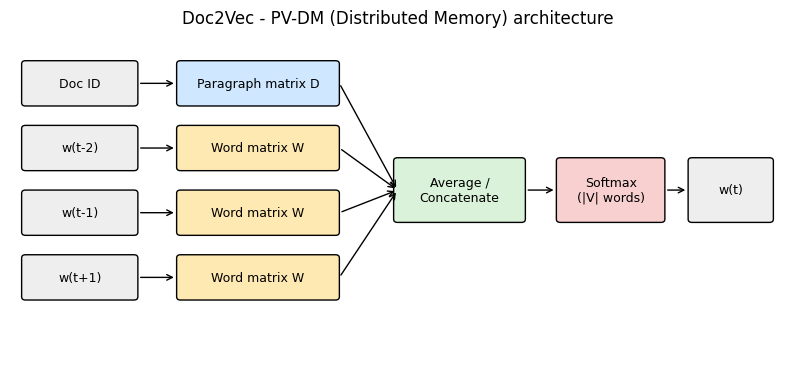

In [6]:
# Doc2Vec (PV-DM) architecture sketch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(10, 4.2)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 5)
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="black"))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9)
rows = [("Doc ID", "Paragraph matrix D", "#cfe8ff", 3.9), ("w(t-2)", "Word matrix W", "#ffe9b3", 2.9),
        ("w(t-1)", "Word matrix W", "#ffe9b3", 1.9), ("w(t+1)", "Word matrix W", "#ffe9b3", 0.9)]
for lab, mat, col, y in rows:
    box(0.2, y, 1.4, 0.6, lab, "#eeeeee"); box(2.2, y, 2.0, 0.6, mat, col)
    ax.annotate("", xy=(2.15, y+0.3), xytext=(1.65, y+0.3), arrowprops=dict(arrowstyle="->"))
    ax.annotate("", xy=(5.0, 2.55), xytext=(4.25, y+0.3), arrowprops=dict(arrowstyle="->"))
box(5.0, 2.1, 1.6, 0.9, "Average /\nConcatenate", "#d9f2d9")
box(7.1, 2.1, 1.3, 0.9, "Softmax\n(|V| words)", "#f9d0d0")
box(8.8, 2.1, 1.0, 0.9, "w(t)", "#eeeeee")
for x0, x1 in [(6.65, 7.05), (8.45, 8.75)]:
    ax.annotate("", xy=(x1, 2.55), xytext=(x0, 2.55), arrowprops=dict(arrowstyle="->"))
ax.set_title("Doc2Vec - PV-DM (Distributed Memory) architecture")
plt.show()

# Part 2 – Fine-tuning BERT for Language Identification

**Task:** fine-tune a base multilingual transformer on the Lab 1 language-ID dataset (23 Indian language/script classes from IndicCorp v2, 80/10/10 stratified split) and compare it with the earlier models (Logistic Regression, MLP, LSTM, GRU, FastText).

**Model:** `xlm-roberta-base` (supports most Indian languages; runs on Colab/Kaggle). Alternatives: `google/muril-base-cased`, `bert-base-multilingual-cased`.

**Setup:** upload `train.csv`, `val.csv`, `test.csv` (produced by the Lab 1 notebook; columns `text`, `language`, `label`) next to this notebook and use a **GPU runtime**. The cells below this point need that data, so run them in Colab/Kaggle or locally with a GPU.

In [7]:
!pip install -q transformers datasets accelerate scikit-learn

In [13]:
import numpy as np, pandas as pd, torch, time
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, f1_score, classification_report

MODEL_NAME = "xlm-roberta-base"   # alternatives: "google/muril-base-cased", "bert-base-multilingual-cased"
MAX_LEN, EPOCHS, LR, BS, SEED = 128, 3, 2e-5, 32, 42

train_df, val_df, test_df = [pd.read_csv(f"{s}.csv") for s in ("/content/train", "/content/val", "/content/test")]
langs = sorted(train_df["language"].unique())
lang2id = {l: i for i, l in enumerate(langs)}; id2lang = {i: l for l, i in lang2id.items()}
for d in (train_df, val_df, test_df):
    d["label"] = d["language"].map(lang2id)
print(len(langs), "languages;", len(train_df), len(val_df), len(test_df))

23 languages; 20493 2553 2576


In [14]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
def enc(batch): return tok(batch["text"], truncation=True, max_length=MAX_LEN)
to_ds = lambda d: Dataset.from_pandas(d[["text", "label"]]).map(enc, batched=True, remove_columns=["text"])
train_ds, val_ds, test_ds = map(to_ds, (train_df, val_df, test_df))

# Sanity check: <unk> rate per language (matters for scripts missing from the tokenizer vocabulary)
unk = tok.unk_token_id
rate = {l: np.mean([np.mean(np.array(tok(t)["input_ids"]) == unk)
                    for t in test_df[test_df.language == l].text[:50]]) for l in langs}
print({k: round(v, 3) for k, v in rate.items() if v > 0.05} or "No language has >5% <unk> tokens")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/20493 [00:00<?, ? examples/s]

Map:   0%|          | 0/2553 [00:00<?, ? examples/s]

Map:   0%|          | 0/2576 [00:00<?, ? examples/s]

{'mni_Mtei': np.float64(0.42), 'santhali': np.float64(0.443)}


In [18]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(langs), id2label=id2lang, label2id=lang2id)

def metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

# Calculate warmup steps manually to avoid version-specific warmup_ratio issues
num_update_steps_per_epoch = len(train_ds) // BS
max_steps = num_update_steps_per_epoch * EPOCHS
warmup_steps = int(0.1 * max_steps)

args = TrainingArguments(
    output_dir="lid_bert", num_train_epochs=EPOCHS, learning_rate=LR,
    per_device_train_batch_size=BS, per_device_eval_batch_size=64,
    weight_decay=0.01, warmup_steps=warmup_steps, eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(), seed=SEED, report_to="none", save_total_limit=1)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
t0 = time.time(); trainer.train(); train_minutes = (time.time() - t0) / 60
print(f"Train time: {train_minutes:.1f} min")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.377779,0.226162,0.904818,0.888987
2,0.225461,0.184416,0.933803,0.931346
3,0.161231,0.149052,0.948296,0.948184


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Train time: 14.9 min


In [19]:
out = trainer.predict(test_ds)
y_pred, y_true = out.predictions.argmax(-1), out.label_ids
bert_acc = accuracy_score(y_true, y_pred); bert_f1 = f1_score(y_true, y_pred, average="macro")
print(f"{MODEL_NAME} test accuracy: {bert_acc:.4f} | macro-F1: {bert_f1:.4f}")
print(classification_report(y_true, y_pred, target_names=langs, digits=4))

xlm-roberta-base test accuracy: 0.9449 | macro-F1: 0.9446
              precision    recall  f1-score   support

    asm_Beng     0.9911    0.9911    0.9911       112
    ben_Beng     1.0000    1.0000    1.0000       112
    brx_Deva     0.9703    0.8750    0.9202       112
    doi_Deva     0.9524    0.8929    0.9217       112
    gom_Deva     0.8131    0.7768    0.7945       112
    guj_Gujr     1.0000    1.0000    1.0000       112
    hin_Deva     0.8217    0.9464    0.8797       112
    kan_Knda     0.9912    1.0000    0.9956       112
    kas_Arab     1.0000    1.0000    1.0000       112
       khasi     0.9573    1.0000    0.9782       112
    mai_Deva     0.9224    0.9554    0.9386       112
    mal_Mlym     1.0000    1.0000    1.0000       112
    mar_Deva     0.8288    0.8214    0.8251       112
    mni_Mtei     0.7377    0.8036    0.7692       112
    npi_Deva     0.9561    0.9732    0.9646       112
    ory_Orya     1.0000    1.0000    1.0000       112
    pan_Guru     1.0000

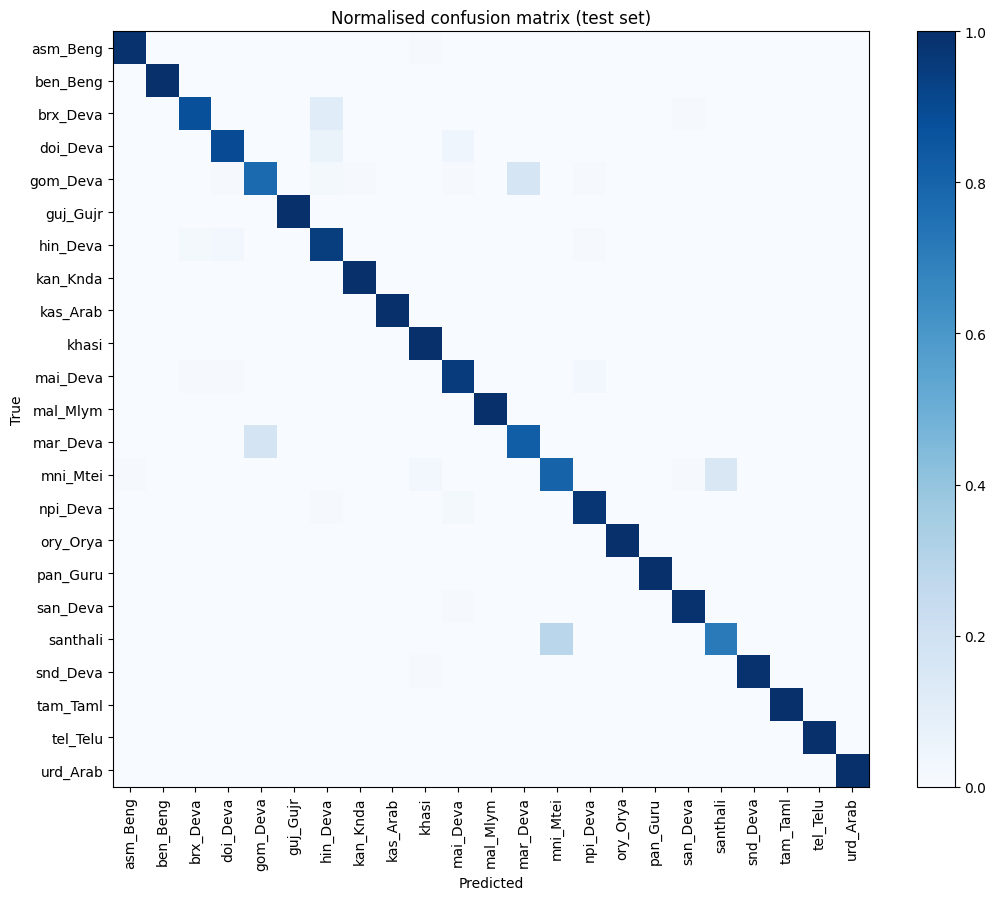

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(11, 9)); im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im)
ax.set_xticks(range(len(langs))); ax.set_xticklabels(langs, rotation=90)
ax.set_yticks(range(len(langs))); ax.set_yticklabels(langs)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalised confusion matrix (test set)")
plt.tight_layout(); plt.show()

## Comparison with the earlier models
Logistic regression numbers come from the Lab 1 notebook. **Fill in the `None` entries** with the test accuracy / macro-F1 from your MLP, LSTM, GRU and FastText notebooks.

,Model,Accuracy,Macro-F1
0,Logistic Regression (TF-IDF word+char n-grams),0.9426,0.9412
1,MLP,NaN,NaN
2,LSTM,NaN,NaN
3,GRU,NaN,NaN
4,FastText,NaN,NaN
5,Fine-tuned xlm-roberta-base,0.9449,0.9446


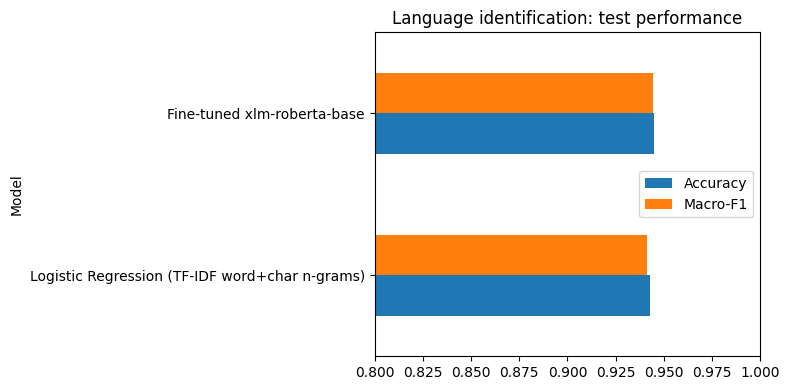

In [21]:
results = pd.DataFrame([
    {"Model": "Logistic Regression (TF-IDF word+char n-grams)", "Accuracy": 0.9426, "Macro-F1": 0.9412},
    {"Model": "MLP",       "Accuracy": None, "Macro-F1": None},   # <- fill in
    {"Model": "LSTM",      "Accuracy": None, "Macro-F1": None},   # <- fill in
    {"Model": "GRU",       "Accuracy": None, "Macro-F1": None},   # <- fill in
    {"Model": "FastText",  "Accuracy": None, "Macro-F1": None},   # <- fill in
    {"Model": f"Fine-tuned {MODEL_NAME}", "Accuracy": round(bert_acc, 4), "Macro-F1": round(bert_f1, 4)},
])
display(results)

plot_df = results.dropna()
ax = plot_df.set_index("Model")[["Accuracy", "Macro-F1"]].plot.barh(figsize=(8, 4), xlim=(0.8, 1.0))
ax.set_title("Language identification: test performance"); plt.tight_layout(); plt.show()

## Observations (edit after running)
- Compare accuracy / macro-F1, training time and model size across all six models.
- Use the confusion matrix and per-language report to find which languages are confused. Closely related Devanagari-script languages (hin, mar, npi, mai, san, doi, brx, gom, snd_Deva) are the usual culprits for every model.
- Check the `<unk>` rate printed earlier. XLM-R's tokenizer has no byte fallback, so scripts it never saw during pretraining (e.g. Meetei Mayek for Manipuri, Ol Chiki for Santali) can collapse into `<unk>` tokens; if those classes do poorly, try MuRIL or mBERT.
- Discuss whether a large pretrained subword model beats character n-gram TF-IDF on a task as easy as language ID, given the extra training cost and model size.